# V1DD embedding coordinates

Read every CCM `EmbeddingSpace` and plot its `EmbeddingLocation` rows. Each data item is colored from the leaf cell-type `Cluster.hex_color` in the `EM_csm_cell_types` hierarchy.

## Import visualization and data libraries

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import polars as pl

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import (
    read_embedding_locations,
    read_embedding_spaces,
)

## Load embedding data and schema

Locate a CCM root containing all required tables, then load embedding definitions, coordinates, leaf clusters, and memberships.

## Validate embedding coordinates and cluster metadata

Require unique coordinate rows and at most one leaf-cluster assignment per data item. Missing cluster assignments are reported and plotted in gray.

## Map cell types to schema colors

Join each leaf assignment to its canonical `Cluster.hex_color`. A missing color on a schema leaf is treated as an error.

## Discover available embedding spaces

Embedding spaces come from the `EmbeddingSpace` table, so newly added spaces are plotted automatically.

In [6]:
PROJECT_ID = "v1dd_1196"
HIERARCHY_ID = "EM_csm_cell_types"
CLUSTER_CATEGORY = "Cluster"
FALLBACK_COLOR = "#c8c8c8"
REQUIRED_TABLES = (
    "embeddingspace",
    "embeddinglocation",
    "cluster",
    "clustermembership",
)

candidate_roots = [
    Path(get_settings().output_root),
    Path("/data/v1dd_1196_ccm"),
]
output_root = next(
    (
        candidate
        for candidate in candidate_roots
        if all((candidate / table).exists() for table in REQUIRED_TABLES)
    ),
    None,
)
if output_root is None:
    raise FileNotFoundError(
        "Could not find the embedding, cluster, and membership CCM tables. "
        "Run the embedding and cell-type ETL notebooks or mount their output."
    )

print(f"Reading CCM tables from: {output_root}")

Reading CCM tables from: /scratch/v1dd_ccm_20261012


In [7]:
embedding_spaces = read_embedding_spaces(
    PROJECT_ID,
    output_root=output_root,
)
embedding_locations = read_embedding_locations(
    PROJECT_ID,
    output_root=output_root,
)
if embedding_spaces.is_empty() or embedding_locations.is_empty():
    raise ValueError(f"No embedding data found for project {PROJECT_ID!r}.")

required_location_columns = {"dataitem_id", "embedding_space", "x", "y"}
missing_columns = required_location_columns - set(embedding_locations.columns)
if missing_columns:
    raise ValueError(f"Embedding locations are missing columns: {sorted(missing_columns)}")
if embedding_locations.select("x", "y").null_count().sum_horizontal().item() > 0:
    raise ValueError("Embedding locations contain null coordinates.")
if (
    embedding_locations
    .select("dataitem_id", "embedding_space")
    .unique()
    .height
    != embedding_locations.height
):
    raise ValueError("An embedding space contains duplicate coordinates for a data item.")

unknown_spaces = set(embedding_locations["embedding_space"].unique()) - set(
    embedding_spaces["id"]
)
if unknown_spaces:
    raise ValueError(f"Locations reference undefined embedding spaces: {unknown_spaces}")

leaf_clusters = (
    pl.read_delta(output_root / "cluster")
    .filter(
        (pl.col("hierarchy_id") == HIERARCHY_ID)
        & (pl.col("hierarchy_category") == CLUSTER_CATEGORY)
    )
    .select("id", "parent", "hex_color")
)
if leaf_clusters.is_empty():
    raise ValueError(f"No leaf clusters found in hierarchy {HIERARCHY_ID!r}.")
if leaf_clusters["hex_color"].null_count() > 0:
    missing_color_ids = leaf_clusters.filter(pl.col("hex_color").is_null())["id"].to_list()
    raise ValueError(f"Leaf clusters are missing schema colors: {missing_color_ids}")

leaf_assignments = (
    pl.read_delta(output_root / "clustermembership")
    .filter(
        (pl.col("project_id") == PROJECT_ID)
        & (pl.col("hierarchy_id") == HIERARCHY_ID)
        & pl.col("cluster").is_in(leaf_clusters["id"].implode())
)
    .select(
        pl.col("item").alias("dataitem_id"),
        pl.col("cluster"),
    )
)
duplicate_assignments = (
    leaf_assignments
    .group_by("dataitem_id")
    .len()
    .filter(pl.col("len") > 1)
)
if not duplicate_assignments.is_empty():
    raise ValueError("Some data items have multiple leaf-cluster assignments.")

colored_assignments = leaf_assignments.join(
    leaf_clusters.rename({"id": "cluster"}),
    on="cluster",
    how="inner",
)
embedding_points = (
    embedding_locations
    .join(colored_assignments, on="dataitem_id", how="left")
    .with_columns(pl.col("hex_color").fill_null(FALLBACK_COLOR))
)

space_stats = embedding_points.group_by("embedding_space").agg(
    pl.len().alias("locations"),
    pl.col("cluster").is_not_null().sum().alias("colored"),
    pl.col("cluster").is_null().sum().alias("unassigned"),
)
space_summary = (
    embedding_spaces
    .select(pl.col("id").alias("embedding_space"), "name")
    .join(space_stats, on="embedding_space", how="left")
    .with_columns(
        pl.col("locations", "colored", "unassigned").fill_null(0)
)
    .sort("name")
)
space_summary

embedding_space,name,locations,colored,unassigned
str,str,u32,u32,u32
"""v1dd_r84_qc_nonnull_umap""","""V1DD r84 QC-nonnull UMAP""",57790,57548,242
"""v1dd_r84_ad_ref_umap""","""V1DD r84 axon-dendrite referen…",39114,39114,0


## Plot each embedding space

Use the leaf cluster's schema color for each assigned data item. The legend collapses inherited leaf colors to their parent cell types, while preserving the explicit `L6b` color.

In [10]:
color_labels = {}
for row in leaf_clusters.iter_rows(named=True):
    label = "L6b" if row["id"].endswith(":L6b") else row["parent"]
    color_labels.setdefault(row["hex_color"], set()).add(label)

def legend_handles(frame):
    used_colors = set(
        frame.filter(pl.col("cluster").is_not_null())["hex_color"].unique()
)
    entries = [
        (" / ".join(sorted(color_labels[color])), color)
        for color in used_colors
    ]
    handles = [
        Patch(facecolor=color, edgecolor="none", label=label)
        for label, color in sorted(entries)
    ]
    if frame["cluster"].null_count() > 0:
        handles.append(
            Patch(facecolor=FALLBACK_COLOR, edgecolor="none", label="Unassigned")
        )
    return handles

def plot_embedding(frame, space_name):
    if frame.is_empty():
        raise ValueError(f"Embedding space {space_name!r} has no locations.")

    assigned = frame.filter(pl.col("cluster").is_not_null())
    unassigned = frame.filter(pl.col("cluster").is_null())
    fig, axis = plt.subplots(figsize=(5, 3), dpi=150)

    if not unassigned.is_empty():
        axis.scatter(
            unassigned["x"].to_numpy(),
            unassigned["y"].to_numpy(),
            s=2,
            alpha=0.35,
            linewidths=0,
            color=FALLBACK_COLOR,
            rasterized=True,
        )
    if not assigned.is_empty():
        axis.scatter(
            assigned["x"].to_numpy(),
            assigned["y"].to_numpy(),
            s=2,
            alpha=0.65,
            linewidths=0,
            color=assigned["hex_color"].to_list(),
            rasterized=True,
        )

    axis.set_xlabel("embedding x")
    axis.set_ylabel("embedding y")
    axis.set_aspect("equal", adjustable="datalim")
    axis.set_title(
        f"{space_name}\n"
        f"{frame.height:,} cells; {assigned.height:,} with a leaf cell type"
    )
    axis.legend(
        handles=legend_handles(frame),
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=8,
    )
    fig.subplots_adjust(right=0.74)
    return fig

## Display embedding visualizations

Render one inline figure for each embedding space.

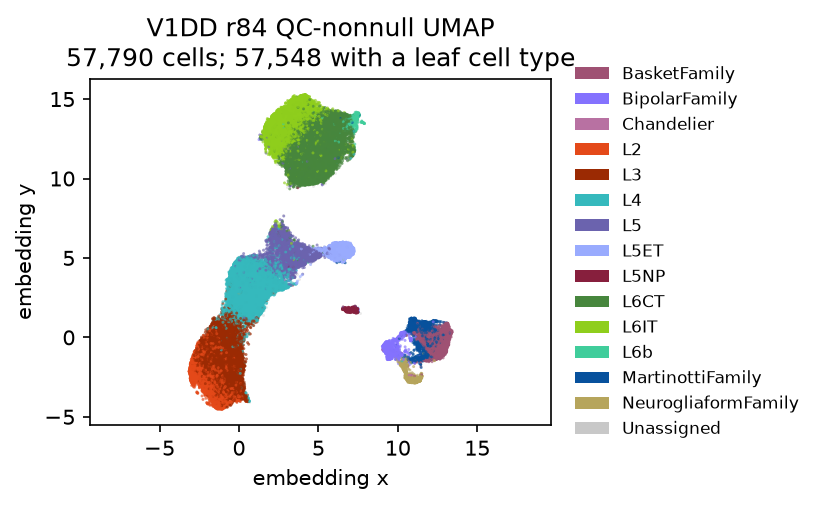

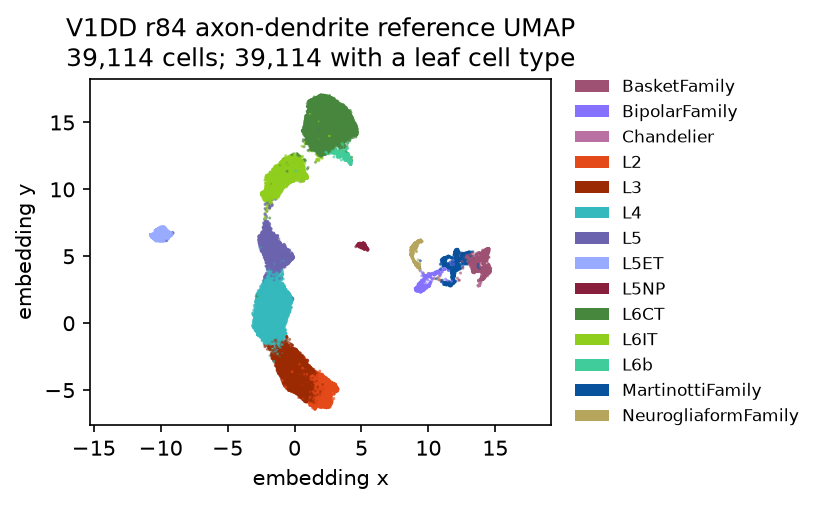

In [11]:
for space in embedding_spaces.sort("name").select("id", "name").iter_rows(named=True):
    frame = embedding_points.filter(pl.col("embedding_space") == space["id"])
    figure = plot_embedding(frame, space["name"])
    plt.show()
    plt.close(figure)